# Практична робота №2. Дерево рішень і випадковий ліс
Класифікація на трьох датасетах з кібербезпеки: Malware Executable Detection, Phishing Websites, NSL-KDD.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

In [2]:
KDD_COLS = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "attack", "level",
]


def load_malware():
    df = pd.read_csv("uci_malware_detection.csv")
    X = df.drop(columns="Label")
    y = (df["Label"] == "malicious").astype(int)
    return train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)


def load_phishing():
    df = pd.read_csv("phishing.csv")
    X = df.drop(columns=["Index", "class"])
    y = (df["class"] == -1).astype(int)
    return train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)


def load_kdd():
    train = pd.read_csv("KDDTrain+.txt", names=KDD_COLS)
    test = pd.read_csv("KDDTest+.txt", names=KDD_COLS)
    both = pd.get_dummies(
        pd.concat([train, test]).drop(columns="level"),
        columns=["protocol_type", "service", "flag"],
    )
    X = both.drop(columns="attack")
    y = (both["attack"] != "normal").astype(int)
    n = len(train)
    return X[:n], X[n:], y[:n], y[n:]

In [3]:
datasets = {"Malware": load_malware(), "Phishing": load_phishing(), "NSL-KDD": load_kdd()}
models = {
    "Decision Tree": lambda: DecisionTreeClassifier(random_state=42),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42),
}

Malware: train (279, 531), test (94, 531), частка класу 1 0.81


Phishing: train (8290, 30), test (2764, 30), частка класу 1 0.44


NSL-KDD: train (125973, 122), test (22544, 122), частка класу 1 0.47


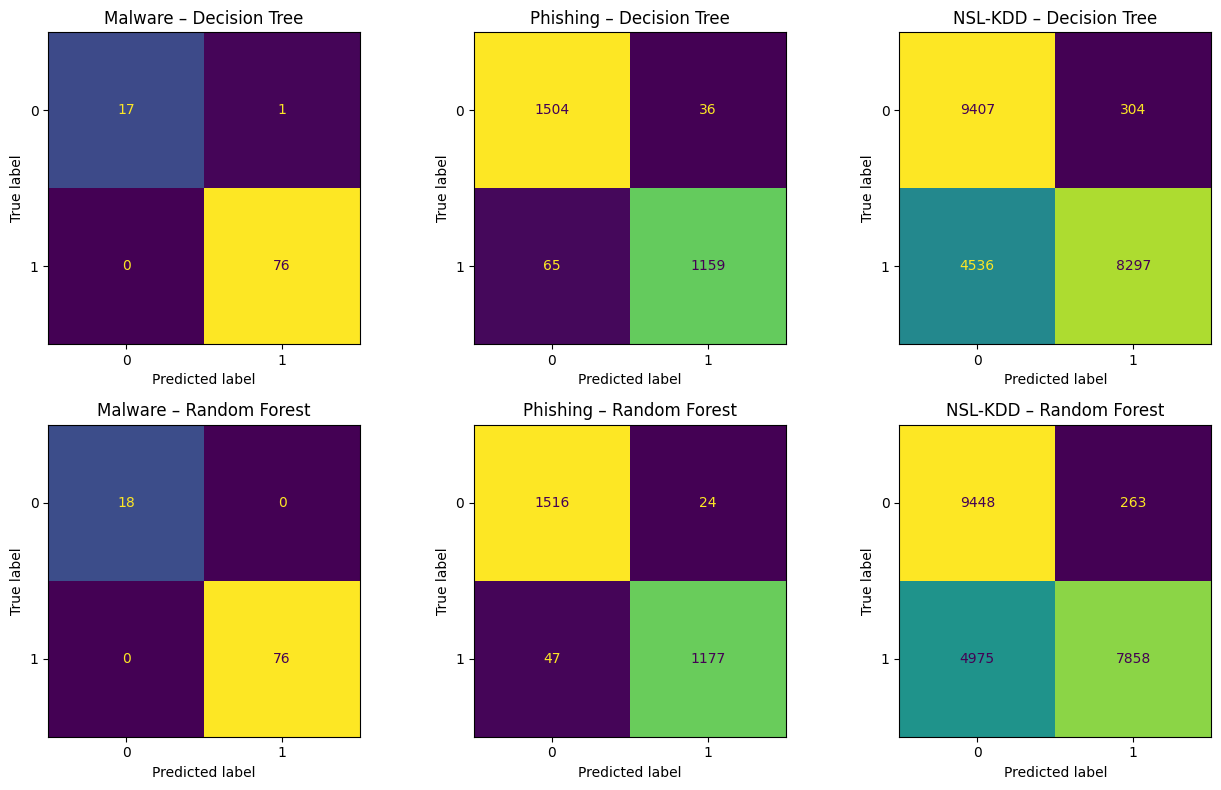

In [4]:
rows, fitted = [], {}
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for j, (dname, (X_train, X_test, y_train, y_test)) in enumerate(datasets.items()):
    print(f"{dname}: train {X_train.shape}, test {X_test.shape}, частка класу 1 {y_train.mean():.2f}")
    for i, (mname, make) in enumerate(models.items()):
        m = make().fit(X_train, y_train)
        fitted[dname, mname] = m
        pred = m.predict(X_test)
        rows.append({
            "Датасет": dname,
            "Модель": mname,
            "Train acc": accuracy_score(y_train, m.predict(X_train)),
            "Test acc": accuracy_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC AUC": roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]),
            "Глибина": m.get_depth() if mname == "Decision Tree" else max(t.get_depth() for t in m.estimators_),
        })
        ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[i, j], colorbar=False)
        axes[i, j].set_title(f"{dname} – {mname}")
plt.tight_layout()
plt.savefig("confusion.png", dpi=110)
plt.show()

In [5]:
res = pd.DataFrame(rows).round(4)
print(res.to_string(index=False))

 Датасет        Модель  Train acc  Test acc     F1  ROC AUC  Глибина
 Malware Decision Tree     1.0000    0.9894 0.9935   0.9722        2
 Malware Random Forest     1.0000    1.0000 1.0000   1.0000        7
Phishing Decision Tree     0.9897    0.9635 0.9582   0.9740       23
Phishing Random Forest     0.9897    0.9743 0.9707   0.9963       28
 NSL-KDD Decision Tree     0.9999    0.7853 0.7742   0.8078       21
 NSL-KDD Random Forest     0.9999    0.7677 0.7500   0.9611       41


In [6]:
train_attacks = set(pd.read_csv("KDDTrain+.txt", names=KDD_COLS)["attack"])
test_attacks = pd.read_csv("KDDTest+.txt", names=KDD_COLS)["attack"]
new = ~test_attacks.isin(train_attacks).values
old = (test_attacks != "normal").values & ~new
X_test = datasets["NSL-KDD"][1]
for mname in models:
    pred = fitted["NSL-KDD", mname].predict(X_test)
    print(f"NSL-KDD {mname}: виявлено відомих атак {pred[old].mean():.3f}, нових {pred[new].mean():.3f} ({new.sum()} записів)")

NSL-KDD Decision Tree: виявлено відомих атак 0.755, нових 0.383 (3750 записів)
NSL-KDD Random Forest: виявлено відомих атак 0.768, нових 0.234 (3750 записів)


Топ-5 ознак RF Malware: {'F_20': 0.056, 'F_19': 0.053, 'F_139': 0.046, 'F_179': 0.042, 'F_140': 0.04}
Топ-5 ознак RF Phishing: {'HTTPS': 0.337, 'AnchorURL': 0.23, 'WebsiteTraffic': 0.076, 'SubDomains': 0.065, 'LinksInScriptTags': 0.042}
Топ-5 ознак RF NSL-KDD: {'src_bytes': 0.145, 'dst_bytes': 0.087, 'flag_SF': 0.084, 'dst_host_srv_count': 0.053, 'same_srv_rate': 0.052}


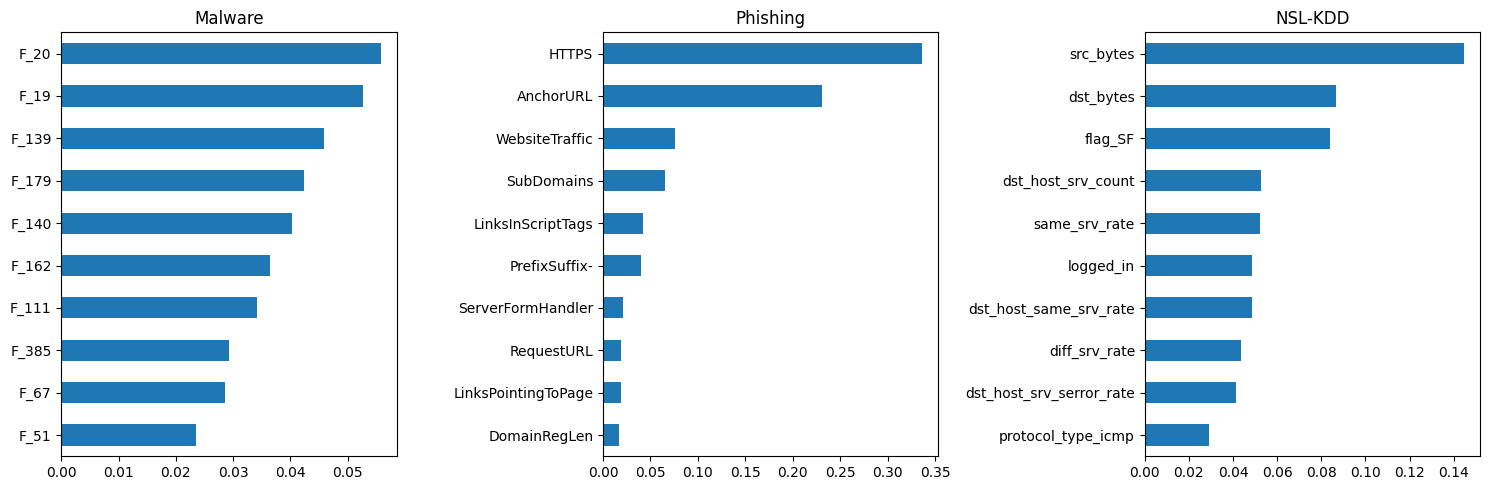

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, dname in zip(axes, datasets):
    X_train = datasets[dname][0]
    imp = pd.Series(fitted[dname, "Random Forest"].feature_importances_, index=X_train.columns)
    imp.nlargest(10)[::-1].plot.barh(ax=ax, title=dname)
    print(f"Топ-5 ознак RF {dname}:", imp.nlargest(5).round(3).to_dict())
plt.tight_layout()
plt.savefig("importance.png", dpi=110)
plt.show()

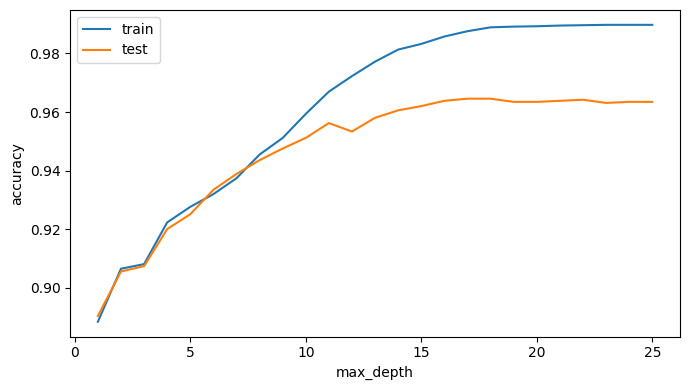

In [8]:
X_train, X_test, y_train, y_test = datasets["Phishing"]
depths = range(1, 26)
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    tr.append(m.score(X_train, y_train))
    te.append(m.score(X_test, y_test))
plt.figure(figsize=(7, 4))
plt.plot(depths, tr, label="train")
plt.plot(depths, te, label="test")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("depth.png", dpi=110)
plt.show()

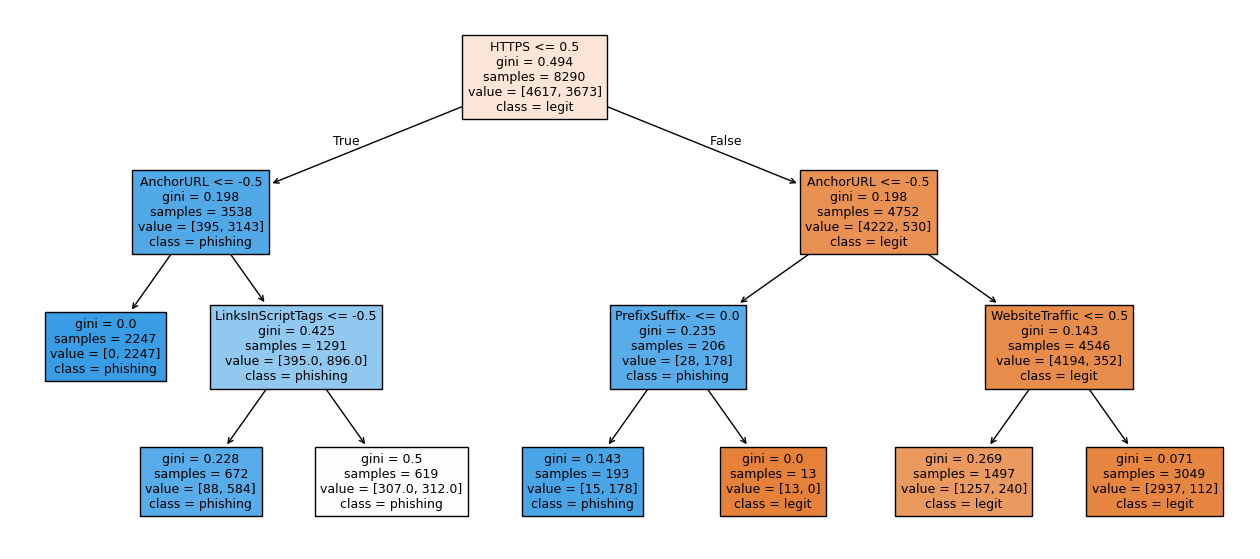

In [9]:
small = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
plt.figure(figsize=(16, 7))
plot_tree(small, feature_names=X_train.columns, class_names=["legit", "phishing"], filled=True, fontsize=9)
plt.savefig("tree.png", dpi=110, bbox_inches="tight")
plt.show()